In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [6]:
columnname=['K','B','C']
data = pd.read_csv(
    "https://raw.githubusercontent.com/selva86/datasets/master/ex2data2.txt",
    names=columnname
)

In [7]:
data.head()

,K,B,C
0,0.051267,0.69956,1
1,-0.092742,0.68494,1
2,-0.213710,0.69225,1
3,-0.375000,0.50219,1
4,-0.513250,0.46564,1


In [8]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 118 entries, 0 to 117
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   K       118 non-null    float64
 1   B       118 non-null    float64
 2   C       118 non-null    int64  
dtypes: float64(2), int64(1)
memory usage: 2.9 KB


In [9]:
data.describe()

,K,B,C
count,118.000000,118.000000,118.000000
mean,0.054779,0.183102,0.491525
std,0.496654,0.519743,0.502060
min,-0.830070,-0.769740,0.000000
25%,-0.372120,-0.254385,0.000000
50%,-0.006336,0.213455,0.000000
75%,0.478970,0.646563,1.000000
max,1.070900,1.108900,1.000000


In [10]:
X_value = data.iloc[:,0:1]
y_value = data.iloc[:,1:2]

In [11]:
X_value

,K
0,0.051267
1,-0.092742
2,-0.213710
3,-0.375000
4,-0.513250
...,...
113,-0.720620
114,-0.593890
115,-0.484450
116,-0.006336


In [12]:
y_value

,B
0,0.699560
1,0.684940
2,0.692250
3,0.502190
4,0.465640
...,...
113,0.538740
114,0.494880
115,0.999270
116,0.999270


In [13]:
from sklearn.model_selection import train_test_split

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X_value, y_value, test_size=0.2, random_state=42
)

In [15]:
print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (94, 1)
X_test: (24, 1)
y_train: (94, 1)
y_test: (24, 1)


In [16]:
from sklearn.linear_model import LinearRegression

In [17]:
model = LinearRegression()

In [18]:
model.fit(X_train, y_train)

LinearRegression()

In [19]:
y_pred = model.predict(X_test)

In [20]:
y_pred

array([[0.17319347],
       [0.18650489],
       [0.19743942],
       [0.10758713],
       [0.11662014],
       [0.15560335],
       [0.08381656],
       [0.12327544],
       [0.19696404],
       [0.08952192],
       [0.16939044],
       [0.21502925],
       [0.11139016],
       [0.1313577 ],
       [0.10188176],
       [0.16843969],
       [0.18840641],
       [0.15084928],
       [0.12232468],
       [0.20980008],
       [0.09189882],
       [0.13088232],
       [0.16178365],
       [0.17224271]])

In [21]:
print("Intercept:", model.intercept_)

Intercept: [0.1550804]


In [22]:
print("Coefficient:", model.coef_)

Coefficient: [[-0.08253097]]


In [23]:
print("Regression Equation:")
print("Salary =", model.intercept_[0], "+", model.coef_[0][0], "* YearsExperience")

Regression Equation:
Salary = 0.15508039977294857 + -0.08253096969106133 * YearsExperience


In [24]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R2 Score:", r2)

R2 Score: -0.03436152933943082


In [25]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", mse)

Mean Squared Error: 0.3267499190402114


In [26]:
rmse = np.sqrt(mse)

print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 0.5716204326650783


In [27]:
result = pd.DataFrame({
    "Actual Salary": y_test.values.ravel(),
    "Predicted Salary": y_pred.ravel()
})

result

,Actual Salary,Predicted Salary
0,-0.016813,0.173193
1,0.918860,0.186505
2,0.465640,0.197439
3,0.268270,0.107587
4,-0.535820,0.116620
5,0.999270,0.155603
6,-0.082602,0.083817
7,-0.565060,0.123275
8,0.904240,0.196964
9,-0.557750,0.089522


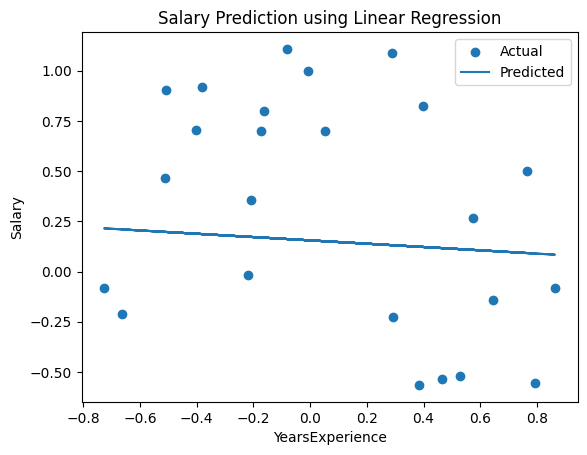

In [28]:
plt.scatter(X_test, y_test, label="Actual")
plt.plot(X_test, y_pred, label="Predicted")

plt.xlabel("YearsExperience")
plt.ylabel("Salary")
plt.title("Salary Prediction using Linear Regression")
plt.legend()
plt.show()

In [29]:
new_experience = [[7]]

predicted_salary = model.predict(new_experience)

print("Predicted Salary:", predicted_salary[0][0])

Predicted Salary: -0.42263638806448073


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
